In [1]:
from pathlib import Path
import pandas as pd

# Diretório onde estão os dados
DATA_DIR = Path("../data/raw")

# Verificar os arquivos disponíveis
arquivos = sorted(DATA_DIR.glob("*.csv"))

print(f"Total de arquivos encontrados: {len(arquivos)}")

for arquivo in arquivos:
    print(arquivo.name)

Total de arquivos encontrados: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [2]:
# Carregar a tabela principal de pedidos
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")

# Visualizar as primeiras linhas
display(orders.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
# Dimensões da tabela
print("Quantidade de linhas e colunas:")
print(orders.shape)

print("\nInformações da tabela:")
orders.info()

print("\nValores ausentes:")
display(orders.isnull().sum())

Quantidade de linhas e colunas:
(99441, 8)

Informações da tabela:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB

Valores ausentes:


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [4]:
# Contar os pedidos por situação
status_counts = orders["order_status"].value_counts()

display(status_counts)

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [5]:
# Calcular a porcentagem de cada situação
status_percent = (
    orders["order_status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(status_percent)

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

In [6]:
# Criar uma cópia para análise
orders_analysis = orders.copy()

# Identificar as colunas de data
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Converter as colunas para datetime
for column in date_columns:
    orders_analysis[column] = pd.to_datetime(
        orders_analysis[column],
        errors="coerce"
    )

# Conferir os tipos de dados
display(orders_analysis[date_columns].dtypes)

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [7]:
# Cruzar o status dos pedidos com a ausência da data de entrega
delivery_status = pd.crosstab(
    orders_analysis["order_status"],
    orders_analysis["order_delivered_customer_date"].isna(),
    margins=True
)

display(delivery_status)

order_delivered_customer_date,False,True,All
order_status,,,
approved,0,2,2
canceled,6,619,625
created,0,5,5
delivered,96470,8,96478
invoiced,0,314,314
processing,0,301,301
shipped,0,1107,1107
unavailable,0,609,609
All,96476,2965,99441


In [8]:
# Selecionar somente pedidos entregues
delivered_orders = orders_analysis[
    orders_analysis["order_status"] == "delivered"
].copy()

# Remover pedidos sem as datas necessárias
delivered_orders = delivered_orders.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

print("Total de pedidos para análise:", len(delivered_orders))  

Total de pedidos para análise: 96470


In [9]:
# Calcular a diferença entre a data real e a estimada
delivered_orders["delivery_delay_days"] = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
    -
    delivered_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

# Criar a variável-alvo
delivered_orders["is_late"] = (
    delivered_orders["delivery_delay_days"] > 0
).astype(int)

display(
    delivered_orders[
        [
            "order_id",
            "order_estimated_delivery_date",
            "order_delivered_customer_date",
            "delivery_delay_days",
            "is_late"
        ]
    ].head(10)
)

,order_id,order_estimated_delivery_date,order_delivered_customer_date,delivery_delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-18,2017-10-10 21:25:13,-8,0
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-13,2018-08-07 15:27:45,-6,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-09-04,2018-08-17 18:06:29,-18,0
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-15,2017-12-02 00:28:42,-13,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-26,2018-02-16 18:17:02,-10,0
5,a4591c265e18cb1dcee52889e2d8acc3,2017-08-01,2017-07-26 10:57:55,-6,0
7,6514b8ad8028c9f2cc2374ded245783f,2017-06-07,2017-05-26 12:55:51,-12,0
8,76c6e866289321a7c93b82b54852dc33,2017-03-06,2017-02-02 14:08:10,-32,0
9,e69bfb5eb88e0ed6a785585b27e16dbf,2017-08-23,2017-08-16 17:14:30,-7,0
10,e6ce16cb79ec1d90b1da9085a6118aeb,2017-06-07,2017-05-29 11:18:31,-9,0


In [10]:
# Contar entregas atrasadas e realizadas no prazo
late_counts = delivered_orders["is_late"].value_counts()

display(late_counts.rename({
    0: "No prazo",
    1: "Atrasadas"
}))

is_late
No prazo     89936
Atrasadas     6534
Name: count, dtype: int64

In [11]:
late_percent = (
    delivered_orders["is_late"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(late_percent.rename({
    0: "No prazo",
    1: "Atrasadas"
}))

is_late
No prazo     93.23
Atrasadas     6.77
Name: proportion, dtype: float64

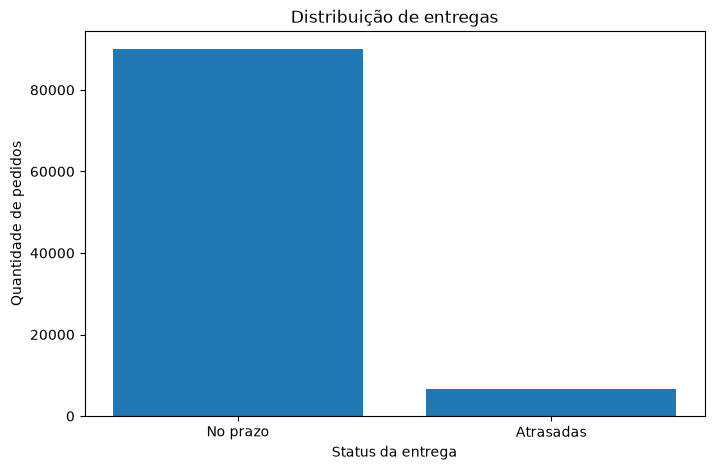

In [12]:
import matplotlib.pyplot as plt

status_labels = ["No prazo", "Atrasadas"]

counts = [
    (delivered_orders["is_late"] == 0).sum(),
    (delivered_orders["is_late"] == 1).sum()
]

plt.figure(figsize=(8, 5))

plt.bar(status_labels, counts)

plt.title("Distribuição de entregas")
plt.xlabel("Status da entrega")
plt.ylabel("Quantidade de pedidos")

plt.show()

In [13]:
# Estatísticas gerais da diferença entre entrega real e estimada

display(
    delivered_orders["delivery_delay_days"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    96470.000000
mean       -11.875889
std         10.182105
min       -147.000000
25%        -17.000000
50%        -12.000000
75%         -7.000000
90%         -2.000000
95%          3.000000
99%         18.000000
max        188.000000
Name: delivery_delay_days, dtype: float64

In [14]:
# Criar uma tabela somente com entregas atrasadas

late_orders = delivered_orders[
    delivered_orders["is_late"] == 1
].copy()

# Analisar quantos dias elas atrasaram

display(
    late_orders["delivery_delay_days"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    6534.000000
mean       10.620141
std        14.644955
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
90%        22.000000
95%        31.000000
99%        71.340000
max       188.000000
Name: delivery_delay_days, dtype: float64

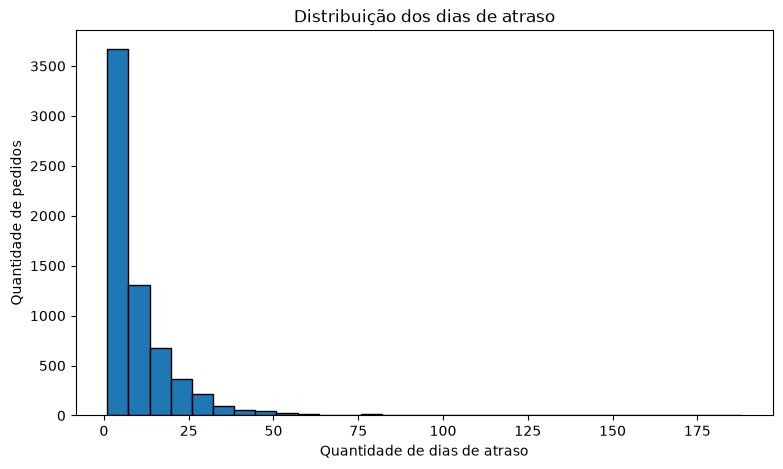

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    late_orders["delivery_delay_days"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribuição dos dias de atraso")
plt.xlabel("Quantidade de dias de atraso")
plt.ylabel("Quantidade de pedidos")

plt.show()

In [16]:
# Carregar as tabelas auxiliares

customers = pd.read_csv(
    DATA_DIR / "olist_customers_dataset.csv"
)

order_items = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv"
)

payments = pd.read_csv(
    DATA_DIR / "olist_order_payments_dataset.csv"
)

products = pd.read_csv(
    DATA_DIR / "olist_products_dataset.csv"
)

sellers = pd.read_csv(
    DATA_DIR / "olist_sellers_dataset.csv"
)

print("Todas as tabelas foram carregadas!")

Todas as tabelas foram carregadas!


In [17]:
# Organizar as tabelas em um dicionário
tables = {
    "Customers": customers,
    "Order Items": order_items,
    "Payments": payments,
    "Products": products,
    "Sellers": sellers
}

# Mostrar quantidade de linhas e colunas
for name, table in tables.items():
    print(f"\n{name}")
    print(f"Linhas: {table.shape[0]}")
    print(f"Colunas: {table.shape[1]}")


Customers
Linhas: 99441
Colunas: 5

Order Items
Linhas: 112650
Colunas: 7

Payments
Linhas: 103886
Colunas: 5

Products
Linhas: 32951
Colunas: 9

Sellers
Linhas: 3095
Colunas: 4


In [18]:
# Analisar as colunas e os valores ausentes

for name, table in tables.items():

    print(f"\n{'=' * 40}")
    print(name)
    print(f"{'=' * 40}")

    print("\nColunas:")
    print(table.columns.tolist())

    print("\nValores ausentes:")
    display(table.isnull().sum()[table.isnull().sum() > 0])


Customers

Colunas:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Valores ausentes:


Series([], dtype: int64)


Order Items

Colunas:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Valores ausentes:


Series([], dtype: int64)


Payments

Colunas:
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Valores ausentes:


Series([], dtype: int64)


Products

Colunas:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Valores ausentes:


product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64


Sellers

Colunas:
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Valores ausentes:


Series([], dtype: int64)

In [19]:
# Verificar linhas duplicadas

for name, table in tables.items():

    print(
        f"{name}: {table.duplicated().sum()} linhas duplicadas"
    )

Customers: 0 linhas duplicadas
Order Items: 0 linhas duplicadas
Payments: 0 linhas duplicadas
Products: 0 linhas duplicadas
Sellers: 0 linhas duplicadas


In [20]:
# Verificar a unicidade das principais identificações

key_checks = {
    "Orders": (orders, "order_id"),
    "Customers": (customers, "customer_id"),
    "Products": (products, "product_id"),
    "Sellers": (sellers, "seller_id")
}

for name, (table, column) in key_checks.items():

    total = len(table)
    unique = table[column].nunique()
    duplicated = table[column].duplicated().sum()

    print(f"\n{name}")
    print(f"Total de registros: {total}")
    print(f"Valores únicos em {column}: {unique}")
    print(f"Identificadores duplicados: {duplicated}")


Orders
Total de registros: 99441
Valores únicos em order_id: 99441
Identificadores duplicados: 0

Customers
Total de registros: 99441
Valores únicos em customer_id: 99441
Identificadores duplicados: 0

Products
Total de registros: 32951
Valores únicos em product_id: 32951
Identificadores duplicados: 0

Sellers
Total de registros: 3095
Valores únicos em seller_id: 3095
Identificadores duplicados: 0


In [21]:
# Analisar quantos registros existem por pedido

order_tables = {
    "Order Items": order_items,
    "Payments": payments
}

for name, table in order_tables.items():

    items_per_order = table.groupby("order_id").size()

    print(f"\n{name}")
    print(f"Pedidos diferentes: {items_per_order.count()}")
    print(f"Média de registros por pedido: {items_per_order.mean():.2f}")
    print(f"Máximo de registros em um pedido: {items_per_order.max()}")


Order Items
Pedidos diferentes: 98666
Média de registros por pedido: 1.14
Máximo de registros em um pedido: 21

Payments
Pedidos diferentes: 99440
Média de registros por pedido: 1.04
Máximo de registros em um pedido: 29


In [22]:
# Verificar integridade das relações entre tabelas

relationships = [
    ("Order Items -> Orders", order_items, "order_id", orders, "order_id"),
    ("Payments -> Orders", payments, "order_id", orders, "order_id"),
    ("Order Items -> Products", order_items, "product_id", products, "product_id"),
    ("Order Items -> Sellers", order_items, "seller_id", sellers, "seller_id"),
    ("Orders -> Customers", orders, "customer_id", customers, "customer_id")
]

for name, child, child_col, parent, parent_col in relationships:

    missing = (~child[child_col].isin(parent[parent_col])).sum()

    print(f"{name}: {missing} referências não encontradas")

Order Items -> Orders: 0 referências não encontradas
Payments -> Orders: 0 referências não encontradas
Order Items -> Products: 0 referências não encontradas
Order Items -> Sellers: 0 referências não encontradas
Orders -> Customers: 0 referências não encontradas


In [23]:
# Identificar pedidos sem itens
orders_without_items = orders[
    ~orders["order_id"].isin(order_items["order_id"])
]

print("Pedidos sem itens:")
print(len(orders_without_items))

print("\nSituação desses pedidos:")
display(orders_without_items["order_status"].value_counts())

Pedidos sem itens:
775

Situação desses pedidos:


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

In [24]:
# Identificar pedidos sem pagamentos
orders_without_payments = orders[
    ~orders["order_id"].isin(payments["order_id"])
]

print("Pedidos sem pagamentos:")
print(len(orders_without_payments))

display(
    orders_without_payments[
        ["order_id", "order_status"]
    ]
)

Pedidos sem pagamentos:
1


,order_id,order_status
30710,bfbd0f9bdef84302105ad712db648a6c,delivered


In [25]:
# Verificar informações ausentes nos pedidos entregues

delivered_without_items = delivered_orders[
    ~delivered_orders["order_id"].isin(order_items["order_id"])
]

delivered_without_payments = delivered_orders[
    ~delivered_orders["order_id"].isin(payments["order_id"])
]

print("Entregues sem itens:", len(delivered_without_items))

print(
    "Entregues sem pagamentos:",
    len(delivered_without_payments)
)

Entregues sem itens: 0
Entregues sem pagamentos: 1


In [26]:
# Identificar o pedido sem registro de pagamento

missing_payment_order_id = orders_without_payments[
    "order_id"
].iloc[0]

print("ID do pedido:")
print(missing_payment_order_id)

print("\nInformações do pedido:")

display(
    orders_analysis[
        orders_analysis["order_id"] == missing_payment_order_id
    ]
)

ID do pedido:
bfbd0f9bdef84302105ad712db648a6c

Informações do pedido:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04


In [27]:
# Verificar os produtos desse pedido

display(
    order_items[
        order_items["order_id"] == missing_payment_order_id
    ]
)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
84389,bfbd0f9bdef84302105ad712db648a6c,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84390,bfbd0f9bdef84302105ad712db648a6c,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83
84391,bfbd0f9bdef84302105ad712db648a6c,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83


In [28]:
# Confirmar que realmente não existem pagamentos

display(
    payments[
        payments["order_id"] == missing_payment_order_id
    ]
)

,order_id,payment_sequential,payment_type,payment_installments,payment_value


In [29]:
# Integrar informações dos produtos aos itens dos pedidos

items_with_products = order_items.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one"
)

print("Itens originais:", len(order_items))
print("Itens após integração:", len(items_with_products))

display(items_with_products.head())

Itens originais: 112650
Itens após integração: 112650


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,58.0,598.0,4.0,650.0,28.0,9.0,14.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,56.0,239.0,2.0,30000.0,50.0,30.0,40.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,59.0,695.0,2.0,3050.0,33.0,13.0,33.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,42.0,480.0,1.0,200.0,16.0,10.0,15.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,59.0,409.0,1.0,3750.0,35.0,40.0,30.0


In [30]:
# Criar características dos produtos por pedido

item_features = (
    items_with_products
    .groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        distinct_products=("product_id", "nunique"),
        distinct_sellers=("seller_id", "nunique"),
        total_item_price=("price", "sum"),
        total_freight=("freight_value", "sum"),
        avg_item_price=("price", "mean"),
        total_product_weight_g=("product_weight_g", "sum"),
        distinct_categories=("product_category_name", "nunique"),
        missing_product_weights=("product_weight_g", lambda x: x.isna().sum()),
        missing_product_categories=("product_category_name", lambda x: x.isna().sum())
    )
    .reset_index()
)

print("Quantidade de pedidos:", len(item_features))

display(item_features.head())

Quantidade de pedidos: 98666


,order_id,item_count,distinct_products,distinct_sellers,total_item_price,total_freight,avg_item_price,total_product_weight_g,distinct_categories,missing_product_weights,missing_product_categories
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,13.29,58.90,650.0,1,0,0
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,19.93,239.90,30000.0,1,0,0
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,17.87,199.00,3050.0,1,0,0
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.79,12.99,200.0,1,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,18.14,199.90,3750.0,1,0,0


In [ ]:
# Criar características dos pagamentos por pedido

payment_features = (
    payments
    .groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum"),
        payment_installments_max=("payment_installments", "max"),
        payment_methods_count=("payment_type", "nunique"),
        payment_records_count=("payment_sequential", "count")
    )
    .reset_index()
)

print("Pedidos com informações de pagamento:", len(payment_features))

display(payment_features.head())

In [ ]:
# Verificar se o pedido sem pagamento foi preservado
# e se suas informações de produtos foram agregadas

display(
    item_features[
        item_features["order_id"] == missing_payment_order_id
    ]
)

display(
    payment_features[
        payment_features["order_id"] == missing_payment_order_id
    ]
)

,order_id,item_count,distinct_products,distinct_sellers,total_item_price,total_freight,avg_item_price,total_product_weight_g,distinct_categories,missing_product_weights,missing_product_categories
73845,bfbd0f9bdef84302105ad712db648a6c,3,1,1,134.97,8.49,44.99,3000.0,1,0,0


,order_id,payment_total,payment_installments_max,payment_methods_count,payment_records_count


In [ ]:
# Carregar novamente as tabelas necessárias

customers = pd.read_csv(
    DATA_DIR / "olist_customers_dataset.csv"
)

order_items = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv"
)

sellers = pd.read_csv(
    DATA_DIR / "olist_sellers_dataset.csv"
)

orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv"
)

print("Tabelas carregadas novamente!")

Tabelas carregadas novamente!


In [ ]:
# Selecionar os vendedores de cada pedido
seller_order = (
    order_items[["order_id", "seller_id"]]
    .drop_duplicates()
    .merge(
        sellers[["seller_id", "seller_state", "seller_city"]],
        on="seller_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        orders[["order_id", "customer_id"]],
        on="order_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        customers[["customer_id", "customer_state"]],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

# Verificar se vendedor e cliente pertencem ao mesmo estado
seller_order["same_state"] = (
    seller_order["seller_state"] == seller_order["customer_state"]
).astype(int)

display(seller_order.head())

,order_id,seller_id,seller_state,seller_city,customer_id,customer_state,same_state
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,SP,volta redonda,3ce436f183e68e07877b285a838db11a,RJ,0
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,SP,sao paulo,f6dd3ec061db4e3987629fe6b26e5cce,SP,1
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,MG,borda da mata,6489ae5e4333f3693df5ad4372dab6d3,MG,1
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,SP,franca,d4eb9395c8c0431ee92fce09860c5a06,SP,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,PR,loanda,58dbd0b2d70206bf40e62cd34e84d795,SP,0


In [ ]:
# Criar características dos vendedores por pedido

seller_features = (
    seller_order
    .groupby("order_id")
    .agg(
        seller_count=("seller_id", "nunique"),
        seller_state_count=("seller_state", "nunique"),
        seller_city_count=("seller_city", "nunique"),
        same_state_seller_count=("same_state", "sum")
    )
    .reset_index()
)

# Calcular a proporção de vendedores do mesmo estado do cliente
seller_features["same_state_seller_share"] = (
    seller_features["same_state_seller_count"]
    / seller_features["seller_count"]
)

print("Quantidade de pedidos:", len(seller_features))

display(seller_features.head())

Quantidade de pedidos: 98666


,order_id,seller_count,seller_state_count,seller_city_count,same_state_seller_count,same_state_seller_share
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,0,0.0
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,1,1.0
2,000229ec398224ef6ca0657da4fc703e,1,1,1,1,1.0
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,1,1.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,0,0.0


In [ ]:
# Criar a base inicial com os pedidos entregues
base = delivered_orders[
    [
        "order_id",
        "customer_id",
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "delivery_delay_days",
        "is_late"
    ]
].copy()

# Integrar informações dos clientes
base = base.merge(
    customers[
        ["customer_id", "customer_city", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Integrar características dos produtos
base = base.merge(
    item_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Integrar características dos pagamentos
base = base.merge(
    payment_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Integrar características dos vendedores
base = base.merge(
    seller_features,
    on="order_id",
    how="left",
    validate="one_to_one"
)

print("Base integrada com sucesso!")
print("Quantidade de registros:", len(base))
print("Quantidade de colunas:", len(base.columns))

display(base.head())

Base integrada com sucesso!
Quantidade de registros: 96470
Quantidade de colunas: 27


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_delay_days,is_late,customer_city,customer_state,item_count,distinct_products,...,missing_product_categories,payment_total,payment_installments_max,payment_methods_count,payment_records_count,seller_count,seller_state_count,seller_city_count,same_state_seller_count,same_state_seller_share
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,-8,0,sao paulo,SP,1,1,...,0,38.71,1.0,2.0,3.0,1,1,1,1,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,-6,0,barreiras,BA,1,1,...,0,141.46,1.0,1.0,1.0,1,1,1,0,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,-18,0,vianopolis,GO,1,1,...,0,179.12,3.0,1.0,1.0,1,1,1,0,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,-13,0,sao goncalo do amarante,RN,1,1,...,0,72.20,1.0,1.0,1.0,1,1,1,0,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,-10,0,santo andre,SP,1,1,...,0,28.62,1.0,1.0,1.0,1,1,1,1,1.0


In [ ]:
# Extrair informações da data da compra

base["purchase_hour"] = (
    base["order_purchase_timestamp"].dt.hour
)

base["purchase_day_of_week"] = (
    base["order_purchase_timestamp"].dt.dayofweek
)

base["purchase_month"] = (
    base["order_purchase_timestamp"].dt.month
)

base["purchase_is_weekend"] = (
    base["purchase_day_of_week"] >= 5
).astype(int)

# Calcular o prazo estimado entre compra e entrega
base["estimated_delivery_window_days"] = (
    base["order_estimated_delivery_date"].dt.normalize()
    -
    base["order_purchase_timestamp"].dt.normalize()
).dt.days

display(
    base[
        [
            "order_id",
            "purchase_hour",
            "purchase_day_of_week",
            "purchase_month",
            "purchase_is_weekend",
            "estimated_delivery_window_days",
            "is_late"
        ]
    ].head(10)
)

C:\Users\Cauan\AppData\Local\Temp\ipykernel_9432\2518143987.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  base["order_purchase_timestamp"].dt.dayofweek


,order_id,purchase_hour,purchase_day_of_week,purchase_month,purchase_is_weekend,estimated_delivery_window_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,10,0,10,0,16,0
1,53cdb2fc8bc7dce0b6741e2150273451,20,1,7,0,20,0
2,47770eb9100c2d0c44946d9cf07ec65d,8,2,8,0,27,0
3,949d5b44dbf5de918fe9c16f97b45f8a,19,5,11,1,27,0
4,ad21c59c0840e6cb83a9ceb5573f8159,21,1,2,0,13,0
5,a4591c265e18cb1dcee52889e2d8acc3,21,6,7,1,23,0
6,6514b8ad8028c9f2cc2374ded245783f,13,1,5,0,22,0
7,76c6e866289321a7c93b82b54852dc33,18,0,1,0,42,0
8,e69bfb5eb88e0ed6a785585b27e16dbf,11,5,7,1,25,0
9,e6ce16cb79ec1d90b1da9085a6118aeb,19,1,5,0,22,0


In [ ]:
# Conferência geral da base

print("Quantidade de linhas:", base.shape[0])
print("Quantidade de colunas:", base.shape[1])

print(
    "Pedidos únicos:",
    base["order_id"].nunique()
)

print(
    "Pedidos duplicados:",
    base["order_id"].duplicated().sum()
)

print("\nDistribuição da variável-alvo:")
display(base["is_late"].value_counts())

print("\nValores ausentes:")
display(
    base.isnull().sum().sort_values(ascending=False)
)

Quantidade de linhas: 96470
Quantidade de colunas: 32
Pedidos únicos: 96470
Pedidos duplicados: 0

Distribuição da variável-alvo:


is_late
0    89936
1     6534
Name: count, dtype: int64


Valores ausentes:


payment_methods_count             1
payment_records_count             1
payment_total                     1
payment_installments_max          1
order_id                          0
customer_id                       0
order_purchase_timestamp          0
order_estimated_delivery_date     0
item_count                        0
distinct_products                 0
distinct_sellers                  0
total_item_price                  0
delivery_delay_days               0
is_late                           0
customer_city                     0
customer_state                    0
distinct_categories               0
total_product_weight_g            0
avg_item_price                    0
total_freight                     0
missing_product_weights           0
missing_product_categories        0
seller_count                      0
seller_state_count                0
seller_city_count                 0
same_state_seller_count           0
same_state_seller_share           0
purchase_hour               

In [ ]:
# Atualizar o dia da semana
base["purchase_day_of_week"] = (
    base["order_purchase_timestamp"].dt.day_of_week
)

# Atualizar a identificação de finais de semana
base["purchase_is_weekend"] = (
    base["purchase_day_of_week"] >= 5
).astype(int)

In [ ]:
# Identificar pedidos com registro de pagamento

base["has_payment_record"] = (
    base["payment_records_count"].notna()
).astype(int)

# Colunas relacionadas aos pagamentos
payment_columns = [
    "payment_total",
    "payment_installments_max",
    "payment_methods_count",
    "payment_records_count"
]

# Preencher valores ausentes com zero
base[payment_columns] = base[payment_columns].fillna(0)

# Conferir o resultado
print("Pedidos com pagamento:")
print(base["has_payment_record"].value_counts())

print("\nValores ausentes:")
display(base.isnull().sum().sort_values(ascending=False).head(10))

Pedidos com pagamento:
has_payment_record
1    96469
0        1
Name: count, dtype: int64

Valores ausentes:


order_id                         0
customer_id                      0
order_purchase_timestamp         0
order_estimated_delivery_date    0
delivery_delay_days              0
is_late                          0
customer_city                    0
customer_state                   0
item_count                       0
distinct_products                0
dtype: int64

In [ ]:
# Definir as colunas que não serão utilizadas como entrada

excluded_columns = [
    "order_id",
    "customer_id",
    "customer_city",
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
    "delivery_delay_days",
    "is_late"
]

# Separar as variáveis de entrada
X = base.drop(columns=excluded_columns)

# Separar a variável que queremos prever
y = base["is_late"]

print("Formato das variáveis X:", X.shape)
print("Formato da variável y:", y.shape)

print("\nColunas utilizadas pelo modelo:")
print(X.columns.tolist())

Formato das variáveis X: (96470, 26)
Formato da variável y: (96470,)

Colunas utilizadas pelo modelo:
['customer_state', 'item_count', 'distinct_products', 'distinct_sellers', 'total_item_price', 'total_freight', 'avg_item_price', 'total_product_weight_g', 'distinct_categories', 'missing_product_weights', 'missing_product_categories', 'payment_total', 'payment_installments_max', 'payment_methods_count', 'payment_records_count', 'seller_count', 'seller_state_count', 'seller_city_count', 'same_state_seller_count', 'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week', 'purchase_month', 'purchase_is_weekend', 'estimated_delivery_window_days', 'has_payment_record']


In [ ]:
# Verificar os tipos de dados das variáveis de entrada

display(X.dtypes)

print("\nValores ausentes em X:")

display(
    X.isnull().sum().sort_values(ascending=False).head(10)
)

print("\nDistribuição da variável-alvo:")

display(y.value_counts())

customer_state                        str
item_count                          int64
distinct_products                   int64
distinct_sellers                    int64
total_item_price                  float64
total_freight                     float64
avg_item_price                    float64
total_product_weight_g            float64
distinct_categories                 int64
missing_product_weights             int64
missing_product_categories          int64
payment_total                     float64
payment_installments_max          float64
payment_methods_count             float64
payment_records_count             float64
seller_count                        int64
seller_state_count                  int64
seller_city_count                   int64
same_state_seller_count             int64
same_state_seller_share           float64
purchase_hour                       int32
purchase_day_of_week                int32
purchase_month                      int32
purchase_is_weekend               


Valores ausentes em X:


customer_state             0
item_count                 0
distinct_products          0
distinct_sellers           0
total_item_price           0
total_freight              0
avg_item_price             0
total_product_weight_g     0
distinct_categories        0
missing_product_weights    0
dtype: int64


Distribuição da variável-alvo:


is_late
0    89936
1     6534
Name: count, dtype: int64

In [ ]:
# Verificar todos os valores ausentes em X

total_missing = X.isnull().sum().sum()

print("Total de valores ausentes:", total_missing)

print("\nColunas com valores ausentes:")

display(
    X.isnull().sum()[X.isnull().sum() > 0]
)

Total de valores ausentes: 0

Colunas com valores ausentes:


Series([], dtype: int64)

In [ ]:
# Ordenar a base pela data da compra

data_model = (
    base
    .sort_values("order_purchase_timestamp")
    .reset_index(drop=True)
)

print("Primeiro pedido:", data_model["order_purchase_timestamp"].min())

print("Último pedido:", data_model["order_purchase_timestamp"].max())

Primeiro pedido: 2016-09-15 12:16:38
Último pedido: 2018-08-29 15:00:37


In [ ]:
# Definir o ponto de divisão
split_index = int(len(data_model) * 0.80)

# Separar os conjuntos
train_data = data_model.iloc[:split_index].copy()

test_data = data_model.iloc[split_index:].copy()

# Separar as variáveis de entrada e a variável-alvo

X_train = train_data.drop(columns=excluded_columns)
y_train = train_data["is_late"]

X_test = test_data.drop(columns=excluded_columns)
y_test = test_data["is_late"]

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

Treinamento: (77176, 26)
Teste: (19294, 26)


In [ ]:
print("PERÍODO DE TREINAMENTO")

print("Início:", train_data["order_purchase_timestamp"].min())
print("Fim:", train_data["order_purchase_timestamp"].max())

print("\nPERÍODO DE TESTE")

print("Início:", test_data["order_purchase_timestamp"].min())
print("Fim:", test_data["order_purchase_timestamp"].max())

PERÍODO DE TREINAMENTO
Início: 2016-09-15 12:16:38
Fim: 2018-05-26 18:16:57

PERÍODO DE TESTE
Início: 2018-05-26 18:18:03
Fim: 2018-08-29 15:00:37


In [ ]:
# Calcular os percentuais de cada conjunto

train_distribution = (
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

test_distribution = (
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("DISTRIBUIÇÃO DO TREINAMENTO:")
display(train_distribution.rename({
    0: "No prazo",
    1: "Atrasadas"
}))

print("\nDISTRIBUIÇÃO DO TESTE:")
display(test_distribution.rename({
    0: "No prazo",
    1: "Atrasadas"
}))

DISTRIBUIÇÃO DO TREINAMENTO:


is_late
No prazo     92.41
Atrasadas     7.59
Name: proportion, dtype: float64


DISTRIBUIÇÃO DO TESTE:


is_late
No prazo     96.51
Atrasadas     3.49
Name: proportion, dtype: float64

In [ ]:
# Separar treinamento e validação dentro dos dados de treinamento

validation_split = int(len(train_data) * 0.80)

fit_data = train_data.iloc[:validation_split].copy()

validation_data = train_data.iloc[validation_split:].copy()

# Separar variáveis de entrada e variável-alvo

X_fit = fit_data.drop(columns=excluded_columns)
y_fit = fit_data["is_late"]

X_val = validation_data.drop(columns=excluded_columns)
y_val = validation_data["is_late"]

# O teste final permanece separado

X_final_test = test_data.drop(columns=excluded_columns)
y_final_test = test_data["is_late"]

print("Treinamento:", X_fit.shape)
print("Validação:", X_val.shape)
print("Teste final:", X_final_test.shape)

Treinamento: (61740, 26)
Validação: (15436, 26)
Teste final: (19294, 26)


In [ ]:
# Comparar a proporção de atrasos nos três conjuntos

distributions = pd.DataFrame({
    "Treinamento": y_fit.value_counts(normalize=True) * 100,
    "Validação": y_val.value_counts(normalize=True) * 100,
    "Teste": y_final_test.value_counts(normalize=True) * 100
}).rename(index={
    0: "No prazo",
    1: "Atrasadas"
}).round(2)

display(distributions)

,Treinamento,Validação,Teste
is_late,,,
No prazo,92.18,93.31,96.51
Atrasadas,7.82,6.69,3.49


In [ ]:
# Verificar os períodos dos três conjuntos

datasets = {
    "Treinamento": fit_data,
    "Validação": validation_data,
    "Teste": test_data
}

for name, dataset in datasets.items():

    print(f"\n{name}")

    print(
        "Início:",
        dataset["order_purchase_timestamp"].min()
    )

    print(
        "Fim:",
        dataset["order_purchase_timestamp"].max()
    )


Treinamento
Início: 2016-09-15 12:16:38
Fim: 2018-03-20 09:15:24

Validação
Início: 2018-03-20 09:16:16
Fim: 2018-05-26 18:16:57

Teste
Início: 2018-05-26 18:18:03
Fim: 2018-08-29 15:00:37


In [ ]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# Identificar as colunas numéricas
numeric_features = X_fit.select_dtypes(
    include="number"
).columns.tolist()

# Identificar as colunas categóricas
categorical_features = [
    column
    for column in X_fit.columns
    if column not in numeric_features
]

print("Variáveis numéricas:", len(numeric_features))
print("Variáveis categóricas:", len(categorical_features))

print("\nColunas categóricas:")
print(categorical_features)

Variáveis numéricas: 25
Variáveis categóricas: 1

Colunas categóricas:
['customer_state']


In [ ]:
# Tratamento das variáveis numéricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Tratamento das variáveis categóricas
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar os dois tratamentos
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Pré-processamento configurado!")

Pré-processamento configurado!


In [ ]:
# Criar o pipeline completo
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Modelo de Regressão Logística criado!")

Modelo de Regressão Logística criado!


In [ ]:
# Treinar utilizando somente os dados de treinamento
logistic_model.fit(X_fit, y_fit)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [ ]:
# Criar o Dummy Classifier
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Treinar o modelo de referência
dummy_model.fit(X_fit, y_fit)

# Realizar previsões na validação
dummy_predictions = dummy_model.predict(X_val)

print("Modelo de referência avaliado!")

Modelo de referência avaliado!


In [ ]:
# Prever as classes
logistic_predictions = logistic_model.predict(X_val)

# Obter as probabilidades de atraso
logistic_probabilities = logistic_model.predict_proba(X_val)[:, 1]

print("Previsões realizadas!")

Previsões realizadas!


In [ ]:
# Função para calcular as métricas
def evaluate_model(name, y_true, predictions, probabilities):

    return {
        "Modelo": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_true, probabilities
        )
    }


# Avaliar os dois modelos
results = pd.DataFrame([
    evaluate_model(
        "Dummy Classifier",
        y_val,
        dummy_predictions,
        dummy_model.predict_proba(X_val)[:, 1]
    ),

    evaluate_model(
        "Logistic Regression",
        y_val,
        logistic_predictions,
        logistic_probabilities
    )
])

display(results.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision
0,Dummy Classifier,0.9331,0.0000,0.0000,0.0000,0.0669
1,Logistic Regression,0.6103,0.1172,0.7393,0.2024,0.1678


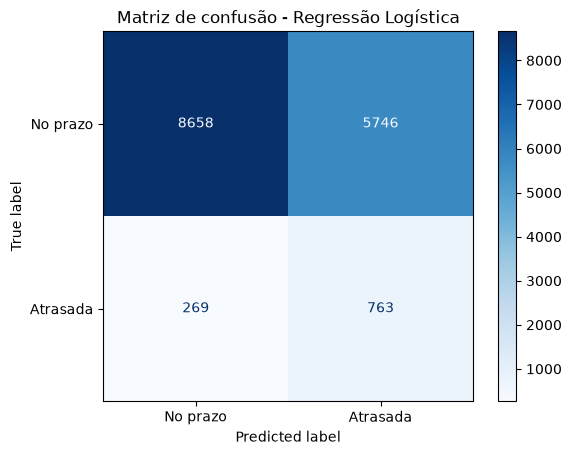

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    logistic_predictions,
    display_labels=["No prazo", "Atrasada"],
    cmap="Blues"
)

plt.title("Matriz de confusão - Regressão Logística")
plt.show()

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Limites que queremos testar
thresholds = [
    0.50,
    0.55,
    0.60,
    0.65,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90
]

threshold_results = []

for threshold in thresholds:

    # Classificar utilizando o threshold escolhido
    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    # Calcular as métricas
    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    # Contar quantos pedidos foram classificados como atrasados
    predicted_late = predictions.sum()

    # Registrar os resultados
    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Predicted Late": predicted_late,
        "Predicted Late (%)": predicted_late / len(predictions) * 100
    })

# Transformar os resultados em DataFrame
threshold_comparison = pd.DataFrame(
    threshold_results
)

display(
    threshold_comparison.round(4)
)

,Threshold,Precision,Recall,F1-score,Predicted Late,Predicted Late (%)
0,0.50,0.1172,0.7393,0.2024,6509,42.1677
1,0.55,0.1403,0.6182,0.2287,4548,29.4636
2,0.60,0.1622,0.5174,0.2470,3292,21.3268
3,0.65,0.1846,0.4215,0.2568,2356,15.2630
4,0.70,0.2157,0.3120,0.2550,1493,9.6722
5,0.75,0.2339,0.1870,0.2079,825,5.3446
6,0.80,0.2518,0.0678,0.1069,278,1.8010
7,0.85,0.2800,0.0203,0.0379,75,0.4859
8,0.90,0.2857,0.0058,0.0114,21,0.1360


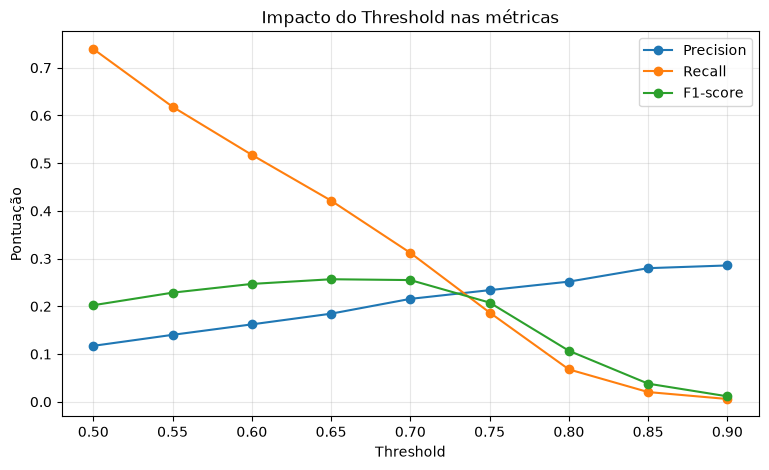

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_comparison["Threshold"],
    threshold_comparison["F1-score"],
    marker="o",
    label="F1-score"
)

plt.title("Impacto do Threshold nas métricas")
plt.xlabel("Threshold")
plt.ylabel("Pontuação")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Encontrar o threshold com melhor F1-score
best_threshold_row = threshold_comparison.loc[
    threshold_comparison["F1-score"].idxmax()
]

print("Melhor threshold:", best_threshold_row["Threshold"])
print("Precision:", best_threshold_row["Precision"])
print("Recall:", best_threshold_row["Recall"])
print("F1-score:", best_threshold_row["F1-score"])
print("Pedidos classificados como atrasados:",
      int(best_threshold_row["Predicted Late"]))

Melhor threshold: 0.65
Precision: 0.18463497453310695
Recall: 0.42151162790697677
F1-score: 0.256788665879575
Pedidos classificados como atrasados: 2356


In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Tratamento das variáveis numéricas
numeric_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Tratamento das variáveis categóricas
categorical_transformer_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combinar os tratamentos
preprocessor_rf = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_rf, numeric_features),
        ("cat", categorical_transformer_rf, categorical_features)
    ]
)

print("Pré-processamento do Random Forest configurado!")

Pré-processamento do Random Forest configurado!


In [ ]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=18,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest criado!")

Random Forest criado!


In [ ]:
# Treinar o Random Forest
rf_model.fit(X_fit, y_fit)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


In [ ]:
# Obter probabilidades de atraso
rf_probabilities = rf_model.predict_proba(X_val)[:, 1]

# Previsões com threshold padrão de 0.50
rf_predictions = (
    rf_probabilities >= 0.50
).astype(int)

print("Previsões do Random Forest realizadas!")

Previsões do Random Forest realizadas!


In [ ]:
# Métricas da Regressão Logística
logistic_metrics = evaluate_model(
    "Logistic Regression",
    y_val,
    logistic_predictions,
    logistic_probabilities
)

# Métricas do Random Forest
rf_metrics = evaluate_model(
    "Random Forest",
    y_val,
    rf_predictions,
    rf_probabilities
)

# Comparar os modelos
model_comparison = pd.DataFrame([
    logistic_metrics,
    rf_metrics
])

display(model_comparison.round(4))

,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision
0,Logistic Regression,0.6103,0.1172,0.7393,0.2024,0.1678
1,Random Forest,0.8792,0.1718,0.2112,0.1895,0.1452


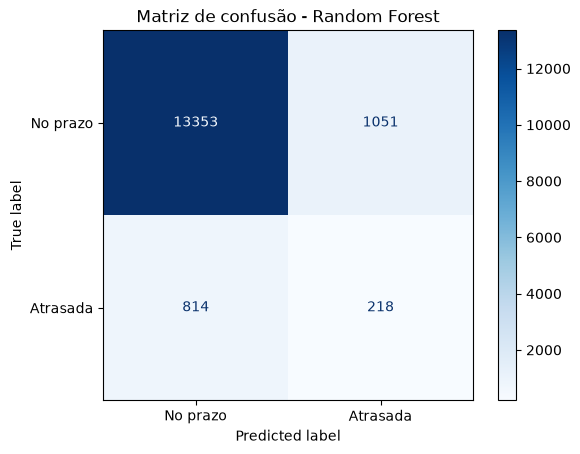

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_predictions,
    display_labels=["No prazo", "Atrasada"],
    cmap="Blues"
)

plt.title("Matriz de confusão - Random Forest")
plt.show()

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [ ]:
# Tratamento das variáveis numéricas
numeric_transformer_hgb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Tratamento das variáveis categóricas
categorical_transformer_hgb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combinar os tratamentos
preprocessor_hgb = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_hgb, numeric_features),
        ("cat", categorical_transformer_hgb, categorical_features)
    ]
)

print("Pré-processamento configurado!")

Pré-processamento configurado!


In [ ]:
hgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor_hgb),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.08,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=1.0,
        class_weight="balanced",
        early_stopping=False,
        random_state=42
    ))
])

print("HistGradientBoosting criado!")

HistGradientBoosting criado!


In [ ]:
hgb_model.fit(X_fit, y_fit)

print("HistGradientBoosting treinado com sucesso!")

HistGradientBoosting treinado com sucesso!


In [ ]:
# Obter probabilidades de atraso
hgb_probabilities = hgb_model.predict_proba(X_val)[:, 1]

# Aplicar threshold padrão
hgb_predictions = (
    hgb_probabilities >= 0.50
).astype(int)

print("Previsões realizadas!")

Previsões realizadas!


In [ ]:
# Avaliar o HistGradientBoosting
hgb_metrics = evaluate_model(
    "HistGradientBoosting",
    y_val,
    hgb_predictions,
    hgb_probabilities
)

# Comparar os três modelos
model_comparison = pd.DataFrame([
    logistic_metrics,
    rf_metrics,
    hgb_metrics
])

display(
    model_comparison
    .sort_values("Average Precision", ascending=False)
    .round(4)
)

,Modelo,Accuracy,Precision,Recall,F1-score,Average Precision
0,Logistic Regression,0.6103,0.1172,0.7393,0.2024,0.1678
1,Random Forest,0.8792,0.1718,0.2112,0.1895,0.1452
2,HistGradientBoosting,0.7251,0.1171,0.4758,0.1879,0.1409


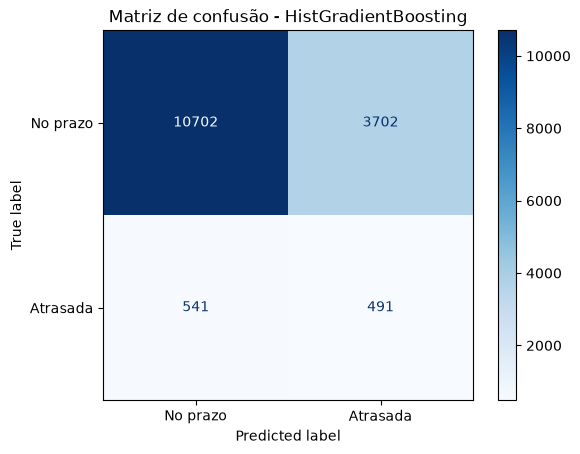

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    hgb_predictions,
    display_labels=["No prazo", "Atrasada"],
    cmap="Blues"
)

plt.title("Matriz de confusão - HistGradientBoosting")
plt.show()

In [ ]:
# Organizar as probabilidades dos três modelos

model_probabilities = {
    "Logistic Regression": logistic_probabilities,
    "Random Forest": rf_probabilities,
    "HistGradientBoosting": hgb_probabilities
}

print("Probabilidades dos três modelos organizadas!")

Probabilidades dos três modelos organizadas!


In [ ]:
import numpy as np

# Limites que serão testados
thresholds = np.arange(0.05, 1.00, 0.05)

threshold_results_all = []

# Testar cada modelo
for model_name, probabilities in model_probabilities.items():

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        precision = precision_score(
            y_val, predictions, zero_division=0
        )

        recall = recall_score(
            y_val, predictions, zero_division=0
        )

        f1 = f1_score(
            y_val, predictions, zero_division=0
        )

        accuracy = accuracy_score(
            y_val, predictions
        )

        threshold_results_all.append({
            "Modelo": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-score": f1,
            "Predicted Late": predictions.sum(),
            "Predicted Late (%)": (
                predictions.sum() / len(predictions)
            ) * 100
        })

# Criar tabela
threshold_comparison_all = pd.DataFrame(
    threshold_results_all
)

display(threshold_comparison_all.round(4))

,Modelo,Threshold,Accuracy,Precision,Recall,F1-score,Predicted Late,Predicted Late (%)
0,Logistic Regression,0.05,0.0693,0.0670,1.0000,0.1256,15398,99.7538
1,Logistic Regression,0.10,0.0742,0.0674,1.0000,0.1262,15322,99.2615
2,Logistic Regression,0.15,0.0803,0.0678,1.0000,0.1269,15228,98.6525
3,Logistic Regression,0.20,0.0901,0.0684,1.0000,0.1281,15077,97.6743
4,Logistic Regression,0.25,0.1076,0.0695,0.9971,0.1300,14801,95.8862
5,Logistic Regression,0.30,0.1553,0.0727,0.9903,0.1355,14051,91.0275
6,Logistic Regression,0.35,0.2231,0.0774,0.9719,0.1433,12966,83.9984
7,Logistic Regression,0.40,0.3454,0.0856,0.9079,0.1565,10946,70.9122
8,Logistic Regression,0.45,0.4747,0.0969,0.8236,0.1733,8776,56.8541
9,Logistic Regression,0.50,0.6103,0.1172,0.7393,0.2024,6509,42.1677


In [ ]:
# Encontrar a melhor configuração de cada algoritmo

best_indices = (
    threshold_comparison_all
    .groupby("Modelo")["F1-score"]
    .idxmax()
)

best_model_thresholds = (
    threshold_comparison_all
    .loc[best_indices]
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)

display(best_model_thresholds.round(4))

,Modelo,Threshold,Accuracy,Precision,Recall,F1-score,Predicted Late,Predicted Late (%)
0,Logistic Regression,0.65,0.8369,0.1846,0.4215,0.2568,2356,15.2630
1,Random Forest,0.40,0.8158,0.1521,0.3837,0.2178,2604,16.8697
2,HistGradientBoosting,0.60,0.8171,0.1462,0.3585,0.2077,2531,16.3967


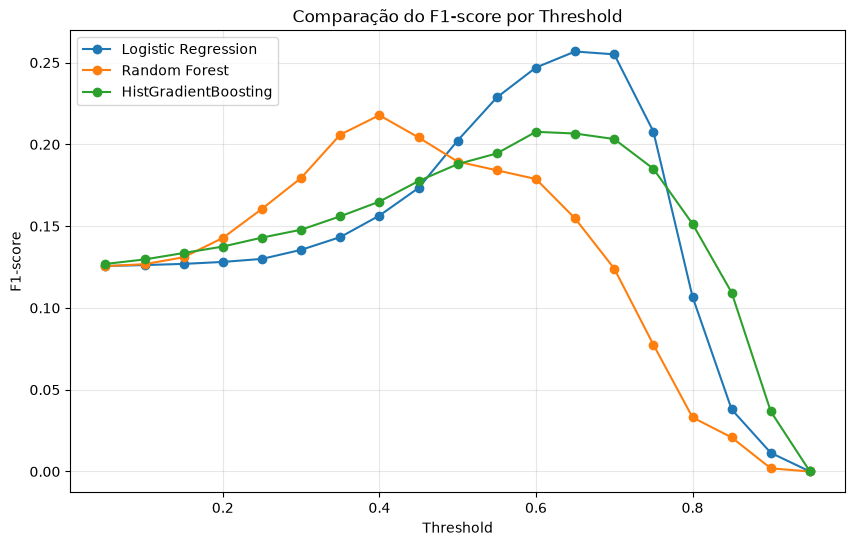

In [ ]:
plt.figure(figsize=(10, 6))

for model_name in threshold_comparison_all["Modelo"].unique():

    model_data = threshold_comparison_all[
        threshold_comparison_all["Modelo"] == model_name
    ]

    plt.plot(
        model_data["Threshold"],
        model_data["F1-score"],
        marker="o",
        label=model_name
    )

plt.title("Comparação do F1-score por Threshold")
plt.xlabel("Threshold")
plt.ylabel("F1-score")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# Testar thresholds mais detalhados
thresholds_fine = np.round(
    np.arange(0.60, 0.701, 0.01),
    2
)

fine_results = []

for threshold in thresholds_fine:

    predictions = (
        logistic_probabilities >= threshold
    ).astype(int)

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Predicted Late": predictions.sum()
    })

fine_comparison = pd.DataFrame(fine_results)

display(fine_comparison.round(4))

,Threshold,Precision,Recall,F1-score,Predicted Late
0,0.60,0.1622,0.5174,0.2470,3292
1,0.61,0.1671,0.5029,0.2509,3105
2,0.62,0.1707,0.4758,0.2513,2876
3,0.63,0.1714,0.4477,0.2479,2695
4,0.64,0.1781,0.4360,0.2530,2526
5,0.65,0.1846,0.4215,0.2568,2356
6,0.66,0.1908,0.4031,0.2590,2180
7,0.67,0.1938,0.3808,0.2569,2028
8,0.68,0.2003,0.3585,0.2570,1847
9,0.69,0.2079,0.3353,0.2567,1664


In [ ]:
best_fine_result = fine_comparison.loc[
    fine_comparison["F1-score"].idxmax()
]

print("Melhor threshold:", best_fine_result["Threshold"])
print("Precision:", best_fine_result["Precision"])
print("Recall:", best_fine_result["Recall"])
print("F1-score:", best_fine_result["F1-score"])
print(
    "Pedidos classificados como atrasados:",
    int(best_fine_result["Predicted Late"])
)

Melhor threshold: 0.66
Precision: 0.1908256880733945
Recall: 0.40310077519379844
F1-score: 0.2590286425902864
Pedidos classificados como atrasados: 2180


In [ ]:
from sklearn.base import clone

In [ ]:
# Valores de C que serão testados
c_values = [0.1, 1.0, 10.0]

# Diferentes formas de tratar o desbalanceamento
class_weights = [None, "balanced"]

# Armazenar os resultados
tuning_results = []

# Guardar os modelos treinados
tuned_models = {}

for c_value in c_values:

    for weight in class_weights:

        model_name = f"C={c_value}_weight={weight}"

        print(f"Treinando: {model_name}")

        # Criar o modelo
        candidate_model = Pipeline(steps=[
            ("preprocessor", clone(preprocessor)),
            ("classifier", LogisticRegression(
                C=c_value,
                class_weight=weight,
                max_iter=1500,
                random_state=42
            ))
        ])

        # Treinar
        candidate_model.fit(X_fit, y_fit)

        # Calcular probabilidades na validação
        probabilities = candidate_model.predict_proba(X_val)[:, 1]

        # Avaliar capacidade de ordenação
        average_precision = average_precision_score(
            y_val,
            probabilities
        )

        # Testar diferentes thresholds
        candidate_thresholds = np.arange(0.01, 1.00, 0.01)

        best_result = None

        for threshold in candidate_thresholds:

            predictions = (
                probabilities >= threshold
            ).astype(int)

            precision = precision_score(
                y_val, predictions, zero_division=0
            )

            recall = recall_score(
                y_val, predictions, zero_division=0
            )

            f1 = f1_score(
                y_val, predictions, zero_division=0
            )

            if best_result is None or f1 > best_result["F1-score"]:

                best_result = {
                    "Threshold": threshold,
                    "Precision": precision,
                    "Recall": recall,
                    "F1-score": f1,
                    "Predicted Late": predictions.sum()
                }

        # Registrar os resultados
        tuning_results.append({
            "Modelo": model_name,
            "C": c_value,
            "Class Weight": str(weight),
            "Average Precision": average_precision,
            **best_result
        })

        tuned_models[model_name] = candidate_model

print("Experimentos concluídos!")

Treinando: C=0.1_weight=None
Treinando: C=0.1_weight=balanced
Treinando: C=1.0_weight=None
Treinando: C=1.0_weight=balanced
Treinando: C=10.0_weight=None
Treinando: C=10.0_weight=balanced
Experimentos concluídos!


In [ ]:
tuning_comparison = pd.DataFrame(tuning_results)

tuning_comparison = tuning_comparison.sort_values(
    "F1-score",
    ascending=False
)

display(tuning_comparison.round(4))

,Modelo,C,Class Weight,Average Precision,Threshold,Precision,Recall,F1-score,Predicted Late
4,C=10.0_weight=None,10.0,None,0.1751,0.15,0.1976,0.3934,0.2630,2055
0,C=0.1_weight=None,0.1,None,0.1734,0.15,0.1986,0.3866,0.2624,2009
2,C=1.0_weight=None,1.0,None,0.1755,0.15,0.1970,0.3924,0.2623,2056
5,C=10.0_weight=balanced,10.0,balanced,0.1678,0.66,0.1915,0.4041,0.2598,2178
3,C=1.0_weight=balanced,1.0,balanced,0.1678,0.66,0.1908,0.4031,0.2590,2180
1,C=0.1_weight=balanced,0.1,balanced,0.1669,0.66,0.1905,0.4002,0.2581,2168


In [ ]:
best_tuning = tuning_comparison.iloc[0]

print("Melhor configuração encontrada:")

print("Modelo:", best_tuning["Modelo"])
print("C:", best_tuning["C"])
print("Class Weight:", best_tuning["Class Weight"])
print("Threshold:", best_tuning["Threshold"])

print("\nMétricas:")

print("Precision:", best_tuning["Precision"])
print("Recall:", best_tuning["Recall"])
print("F1-score:", best_tuning["F1-score"])
print("Average Precision:", best_tuning["Average Precision"])

Melhor configuração encontrada:
Modelo: C=10.0_weight=None
C: 10.0
Class Weight: None
Threshold: 0.15000000000000002

Métricas:
Precision: 0.19756690997566909
Recall: 0.39341085271317827
F1-score: 0.26303854875283444
Average Precision: 0.17507667356099083


In [ ]:
# Recuperar o melhor modelo treinado
best_tuned_model = tuned_models[best_tuning["Modelo"]]

# Obter probabilidades na validação
best_tuned_probabilities = (
    best_tuned_model.predict_proba(X_val)[:, 1]
)

# Testar thresholds próximos de 0.15
refined_thresholds = np.round(
    np.arange(0.10, 0.201, 0.005),
    3
)

refined_results = []

for threshold in refined_thresholds:

    predictions = (
        best_tuned_probabilities >= threshold
    ).astype(int)

    refined_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Predicted Late": predictions.sum()
    })

refined_comparison = pd.DataFrame(refined_results)

display(refined_comparison.round(4))

,Threshold,Precision,Recall,F1-score,Predicted Late
0,0.100,0.1459,0.6047,0.2350,4278
1,0.105,0.1509,0.5717,0.2388,3909
2,0.110,0.1585,0.5543,0.2465,3609
3,0.115,0.1647,0.5320,0.2515,3333
4,0.120,0.1694,0.5087,0.2541,3100
5,0.125,0.1720,0.4777,0.2530,2866
6,0.130,0.1759,0.4564,0.2539,2678
7,0.135,0.1800,0.4390,0.2553,2517
8,0.140,0.1851,0.4205,0.2570,2345
9,0.145,0.1910,0.4050,0.2596,2188


In [ ]:
best_refined = refined_comparison.loc[
    refined_comparison["F1-score"].idxmax()
]

print("Melhor threshold:", best_refined["Threshold"])
print("Precision:", best_refined["Precision"])
print("Recall:", best_refined["Recall"])
print("F1-score:", best_refined["F1-score"])
print(
    "Pedidos sinalizados:",
    int(best_refined["Predicted Late"])
)

Melhor threshold: 0.15
Precision: 0.19756690997566909
Recall: 0.39341085271317827
F1-score: 0.26303854875283444
Pedidos sinalizados: 2055


In [ ]:
from sklearn.inspection import permutation_importance

In [ ]:
# Identificar a melhor configuração encontrada
best_config = tuning_comparison.sort_values(
    "F1-score",
    ascending=False
).iloc[0]

# Recuperar o modelo treinado
selected_model = tuned_models[best_config["Modelo"]]

# Definir o threshold escolhido
selected_threshold = float(best_refined["Threshold"])

print("Modelo:", best_config["Modelo"])
print("Threshold:", selected_threshold)

Modelo: C=10.0_weight=None
Threshold: 0.15


In [ ]:
# Calcular a importância das variáveis
permutation_result = permutation_importance(
    selected_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

print("Importância das variáveis calculada!")

Importância das variáveis calculada!


In [ ]:
# Criar tabela de importância
feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
})

# Ordenar da maior para a menor importância
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.round(5))

,Feature,Importance,Std
0,customer_state,0.08409,0.00204
24,estimated_delivery_window_days,0.05763,0.00214
19,same_state_seller_share,0.03456,0.00251
6,avg_item_price,0.02212,0.00453
11,payment_total,0.00989,0.00153
4,total_item_price,0.00824,0.00143
5,total_freight,0.00383,0.00100
18,same_state_seller_count,0.00265,0.00086
22,purchase_month,0.00260,0.00030
21,purchase_day_of_week,0.00123,0.00045


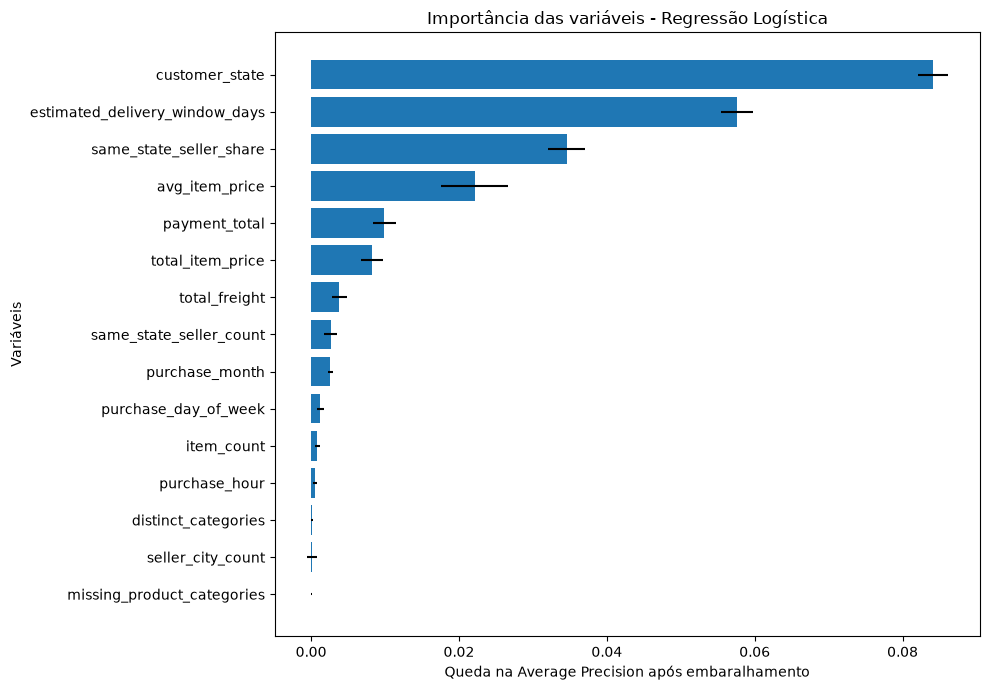

In [ ]:
# Selecionar as 15 principais variáveis
top_features = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.title("Importância das variáveis - Regressão Logística")
plt.xlabel("Queda na Average Precision após embaralhamento")
plt.ylabel("Variáveis")

plt.tight_layout()
plt.show()

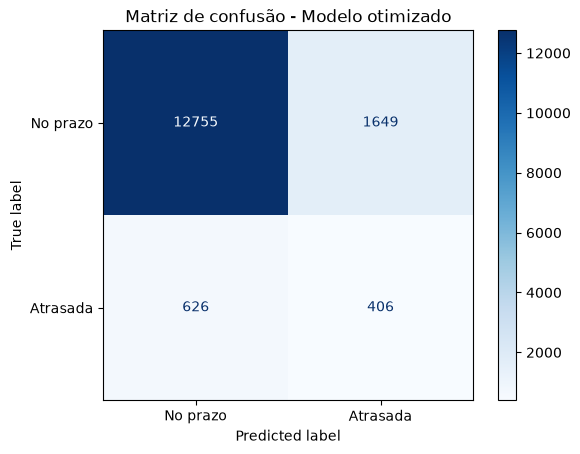

In [ ]:
# Obter probabilidades na validação
selected_probabilities = selected_model.predict_proba(X_val)[:, 1]

# Aplicar o threshold escolhido
selected_predictions = (
    selected_probabilities >= selected_threshold
).astype(int)

# Criar matriz de confusão
ConfusionMatrixDisplay.from_predictions(
    y_val,
    selected_predictions,
    display_labels=["No prazo", "Atrasada"],
    cmap="Blues"
)

plt.title("Matriz de confusão - Modelo otimizado")
plt.show()

In [ ]:
# Relatório completo de classificação
print(
    classification_report(
        y_val,
        selected_predictions,
        target_names=["No prazo", "Atrasada"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No prazo       0.95      0.89      0.92     14404
    Atrasada       0.20      0.39      0.26      1032

    accuracy                           0.85     15436
   macro avg       0.58      0.64      0.59     15436
weighted avg       0.90      0.85      0.87     15436



In [ ]:
# Salvar os experimentos de Regressão Logística

experiment_summary = tuning_comparison.copy()

experiment_summary["Dataset"] = "Validation"
experiment_summary["Selection_Metric"] = "F1-score"

experiment_summary.to_csv(
    REPORTS_DIR / "experimentos_regressao_logistica.csv",
    index=False
)

# Salvar a importância das variáveis
feature_importance.to_csv(
    REPORTS_DIR / "importancia_variaveis.csv",
    index=False
)

# Salvar a comparação dos três algoritmos
model_comparison.to_csv(
    REPORTS_DIR / "comparacao_modelos.csv",
    index=False
)

# Salvar os experimentos com thresholds
threshold_comparison_all.to_csv(
    REPORTS_DIR / "comparacao_thresholds.csv",
    index=False
)

print("Todos os relatórios foram salvos!")

NameError: name 'REPORTS_DIR' is not defined

In [ ]:
from pathlib import Path

# Identificar a raiz do projeto
PROJECT_DIR = DATA_DIR.resolve().parents[1]

# Definir a pasta de relatórios
REPORTS_DIR = PROJECT_DIR / "reports"

# Criar a pasta caso ainda não exista
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Raiz do projeto:", PROJECT_DIR)
print("Pasta de relatórios:", REPORTS_DIR)
print("Pasta preparada com sucesso!")

Raiz do projeto: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml
Pasta de relatórios: D:\EstagioIFood\AI_Engineer\delivery-prediction-ml\reports
Pasta preparada com sucesso!


In [ ]:
import sys
from pathlib import Path

# Identificar a raiz do projeto
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Adicionar o projeto ao caminho de importação
sys.path.insert(0, str(PROJECT_DIR))

from src.preprocessing import (
    build_feature_base,
    make_temporal_splits
)

# Localização dos CSVs
DATA_DIR = PROJECT_DIR / "data" / "raw"

# Reconstruir a base
base_rebuilt = build_feature_base(DATA_DIR)

print("Base reconstruída!")
print("Registros:", base_rebuilt.shape[0])
print("Colunas:", base_rebuilt.shape[1])

display(base_rebuilt.head())

Base reconstruída!
Registros: 96470
Colunas: 33


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,delivery_delay_days,is_late,customer_city,customer_state,item_count,distinct_products,...,seller_state_count,seller_city_count,same_state_seller_count,has_payment_record,purchase_hour,purchase_day_of_week,purchase_month,purchase_is_weekend,estimated_delivery_window_days,same_state_seller_share
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,-8,0,sao paulo,SP,1,1,...,1,1,1,1,10,0,10,0,16,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,-6,0,barreiras,BA,1,1,...,1,1,0,1,20,1,7,0,20,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,-18,0,vianopolis,GO,1,1,...,1,1,0,1,8,2,8,0,27,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,-13,0,sao goncalo do amarante,RN,1,1,...,1,1,0,1,19,5,11,1,27,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,-10,0,santo andre,SP,1,1,...,1,1,1,1,21,1,2,0,13,1.0


In [ ]:
# Criar os conjuntos de dados
splits = make_temporal_splits(base_rebuilt)

# Conferir as dimensões
for name in ["X_fit", "X_val", "X_test"]:
    print(name, splits[name].shape)

X_fit (61740, 26)
X_val (15436, 26)
X_test (19294, 26)


In [ ]:
print("Base original:", base.shape)
print("Base reconstruída:", base_rebuilt.shape)

print("\nColunas existentes somente na base original:")

print(
    sorted(set(base.columns) - set(base_rebuilt.columns))
)

print("\nColunas existentes somente na base reconstruída:")

print(
    sorted(set(base_rebuilt.columns) - set(base.columns))
)

print("\nColunas duplicadas na reconstruída:")

print(
    base_rebuilt.columns[
        base_rebuilt.columns.duplicated()
    ].tolist()
)

Base original: (96470, 33)
Base reconstruída: (96470, 33)

Colunas existentes somente na base original:
[]

Colunas existentes somente na base reconstruída:
[]

Colunas duplicadas na reconstruída:
[]


In [ ]:
from src.train import (
    train_model,
    evaluate_at_threshold,
    save_model
)

# Treinar o modelo com os dados de treinamento
model = train_model(X_fit, y_fit)

print("Modelo treinado pelo módulo train.py!")

Modelo treinado pelo módulo train.py!


In [ ]:
import src.train as train_module

print("Arquivo carregado:")
print(train_module.__file__)

print("\nFunções disponíveis:")

print([
    name
    for name in dir(train_module)
    if not name.startswith("_")
])

Arquivo carregado:
d:\EstagioIFood\AI_Engineer\delivery-prediction-ml\src\train.py

Funções disponíveis:
['ColumnTransformer', 'LogisticRegression', 'OneHotEncoder', 'Path', 'Pipeline', 'SimpleImputer', 'StandardScaler', 'accuracy_score', 'average_precision_score', 'build_logistic_pipeline', 'confusion_matrix', 'evaluate_at_threshold', 'f1_score', 'joblib', 'precision_score', 'recall_score', 'save_model', 'train_model']


In [ ]:
import importlib

importlib.reload(train_module)

print("Módulo atualizado!")

Módulo atualizado!


In [ ]:
from src.train import (
    train_model,
    evaluate_at_threshold,
    save_model
)

print("Funções importadas com sucesso!")

Funções importadas com sucesso!


In [ ]:
# Avaliar o modelo na validação
metrics, matrix, predictions, probabilities = (
    evaluate_at_threshold(
        model,
        X_val,
        y_val,
        threshold=0.15
    )
)

# Exibir as métricas
display(
    pd.DataFrame([metrics]).round(4)
)

# Exibir a matriz de confusão
print("Matriz de confusão:")
print(matrix)

,Accuracy,Precision,Recall,F1-score,Average Precision
0,0.8526,0.1976,0.3934,0.263,0.1751


Matriz de confusão:
[[12755  1649]
 [  626   406]]


In [ ]:
# Ordenar as duas bases pelo identificador do pedido
original_sorted = (
    base.sort_values("order_id").reset_index(drop=True)
)

rebuilt_sorted = (
    base_rebuilt.sort_values("order_id").reset_index(drop=True)
)

# Comparar o conteúdo das bases
try:
    pd.testing.assert_frame_equal(
        original_sorted,
        rebuilt_sorted,
        check_dtype=False
    )

    print("As duas bases possuem dados equivalentes!")

except AssertionError as error:
    print("Encontramos diferenças entre as bases:")
    print(error)

Encontramos diferenças entre as bases:
DataFrame.columns are different

DataFrame.columns values are different (6.06061 %)
[left]:  Index(['order_id', 'customer_id', 'order_purchase_timestamp',
       'order_estimated_delivery_date', 'delivery_delay_days', 'is_late',
       'customer_city', 'customer_state', 'item_count', 'distinct_products',
       'distinct_sellers', 'total_item_price', 'total_freight',
       'avg_item_price', 'total_product_weight_g', 'distinct_categories',
       'missing_product_weights', 'missing_product_categories',
       'payment_total', 'payment_installments_max', 'payment_methods_count',
       'payment_records_count', 'seller_count', 'seller_state_count',
       'seller_city_count', 'same_state_seller_count',
       'same_state_seller_share', 'purchase_hour', 'purchase_day_of_week',
       'purchase_month', 'purchase_is_weekend',
       'estimated_delivery_window_days', 'has_payment_record'],
      dtype='str')
[right]: Index(['order_id', 'customer_id', 'o

In [ ]:
import importlib
import src.preprocessing as preprocessing

# Atualizar o módulo
importlib.reload(preprocessing)

# Reconstruir a base
base_rebuilt = preprocessing.build_feature_base(DATA_DIR)

print("Base reconstruída:", base_rebuilt.shape)
print("Base original:", base.shape)

Base reconstruída: (96470, 33)
Base original: (96470, 33)


In [ ]:
# Ordenar as duas bases pelo identificador do pedido
original_sorted = (
    base.sort_values("order_id").reset_index(drop=True)
)

rebuilt_sorted = (
    base_rebuilt.sort_values("order_id").reset_index(drop=True)
)

# Comparar os dados
try:
    pd.testing.assert_frame_equal(
        original_sorted,
        rebuilt_sorted,
        check_dtype=False
    )

    print("SUCESSO: as duas bases são equivalentes!")

except AssertionError as error:
    print("Ainda existem diferenças:")
    print(error)

SUCESSO: as duas bases são equivalentes!


In [ ]:
import importlib
import src.predict as predict_module

# Conferir o caminho do arquivo
print("Arquivo carregado:")
print(predict_module.__file__)

# Conferir as funções disponíveis
print("\nFunções disponíveis:")

print([
    name
    for name in dir(predict_module)
    if not name.startswith("_")
])

Arquivo carregado:
d:\EstagioIFood\AI_Engineer\delivery-prediction-ml\src\predict.py

Funções disponíveis:
[]


In [ ]:
# Atualizar o módulo com o conteúdo atual do arquivo
importlib.reload(predict_module)

print("Módulo atualizado!")

print("\nFunções disponíveis:")

print([
    name
    for name in dir(predict_module)
    if not name.startswith("_")
])

Módulo atualizado!

Funções disponíveis:
['Path', 'joblib', 'load_model', 'pd', 'predict_late']


In [ ]:
from src.predict import predict_late

# Selecionar dez pedidos da validação
sample_orders = X_val.head(10)

# Realizar previsões
sample_predictions = predict_late(
    selected_model,
    sample_orders,
    threshold=selected_threshold
)

display(sample_predictions)

,late_probability,predicted_is_late
61740,0.095876,0
61741,0.022423,0
61742,0.023277,0
61743,0.069036,0
61744,0.052586,0
61745,0.172196,1
61746,0.053402,0
61747,0.027168,0
61748,0.181611,1
61749,0.071916,0


In [ ]:
print("Pedidos analisados:", len(sample_predictions))

print(
    "Pedidos classificados como atrasados:",
    sample_predictions["predicted_is_late"].sum()
)

print(
    "Pedidos classificados no prazo:",
    (sample_predictions["predicted_is_late"] == 0).sum()
)

Pedidos analisados: 10
Pedidos classificados como atrasados: 2
Pedidos classificados no prazo: 8


In [ ]:
try:

    predict_late(
        selected_model,
        sample_orders,
        threshold=1.5
    )

except ValueError as error:

    print("Erro identificado corretamente:")
    print(error)

Erro identificado corretamente:
O threshold deve estar entre 0 e 1.


In [ ]:
from pathlib import Path
import sys

# Procurar a pasta do projeto no diretório atual e seus pais
PROJECT_DIR = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "src" / "preprocessing.py").is_file():
        PROJECT_DIR = folder
        break

# Caminho conhecido do nosso projeto, como alternativa
if PROJECT_DIR is None:
    PROJECT_DIR = Path(
        r"D:\EstagioIFood\AI_Engineer\delivery-prediction-ml"
    )

# Verificar se a estrutura existe
if not (PROJECT_DIR / "src" / "preprocessing.py").is_file():
    raise FileNotFoundError("Não foi possível localizar a pasta src.")

# Adicionar a raiz do projeto ao caminho de importação
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("Projeto localizado:", PROJECT_DIR)
print("Pasta src encontrada:", (PROJECT_DIR / "src").exists())

Projeto localizado: d:\EstagioIFood\AI_Engineer\delivery-prediction-ml
Pasta src encontrada: True


In [ ]:
from src.preprocessing import EXCLUDED_COLUMNS
from src.train import train_model, evaluate_at_threshold

# Reunir treinamento e validação
development_data = pd.concat([
    fit_data,
    validation_data
]).sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

# Preparar as variáveis de entrada
X_dev = development_data.drop(
    columns=EXCLUDED_COLUMNS
)

y_dev = development_data["is_late"]

# Recuperar o teste final
X_test = test_data.drop(columns=EXCLUDED_COLUMNS)
y_test = test_data["is_late"]

print("Desenvolvimento:", X_dev.shape)
print("Teste final:", X_test.shape)

Desenvolvimento: (77176, 26)
Teste final: (19294, 26)


In [ ]:
# Treinar utilizando todo o conjunto de desenvolvimento
final_model = train_model(X_dev, y_dev)

print("Modelo final treinado!")

Modelo final treinado!


In [ ]:
# Avaliar no conjunto de teste reservado
final_metrics, final_matrix, final_predictions, final_probabilities = (
    evaluate_at_threshold(
        final_model,
        X_test,
        y_test,
        threshold=0.15
    )
)

# Mostrar métricas
display(
    pd.DataFrame([final_metrics]).round(4)
)

# Mostrar matriz de confusão
print("Matriz de confusão:")
print(final_matrix)

,Accuracy,Precision,Recall,F1-score,Average Precision
0,0.845,0.0673,0.2671,0.1075,0.0716


Matriz de confusão:
[[16124  2496]
 [  494   180]]


In [ ]:
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No prazo", "Atrasada"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No prazo       0.97      0.87      0.92     18620
    Atrasada       0.07      0.27      0.11       674

    accuracy                           0.85     19294
   macro avg       0.52      0.57      0.51     19294
weighted avg       0.94      0.85      0.89     19294



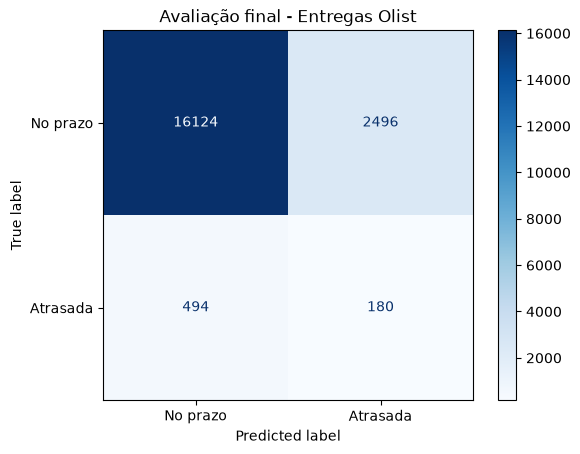

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    display_labels=["No prazo", "Atrasada"],
    cmap="Blues"
)

plt.title("Avaliação final - Entregas Olist")
plt.show()

In [ ]:
from src.train import save_model

print("Função save_model importada com sucesso!")

Função save_model importada com sucesso!


In [ ]:
from pathlib import Path

# Definir a raiz do projeto, caso necessário
if "PROJECT_DIR" not in globals():
    PROJECT_DIR = Path(
        r"D:\EstagioIFood\AI_Engineer\delivery-prediction-ml"
    )

# Definir a pasta de relatórios
REPORTS_DIR = PROJECT_DIR / "reports"

# Garantir que a pasta exista
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Pasta de relatórios:", REPORTS_DIR)
print("Pasta encontrada:", REPORTS_DIR.exists())

Pasta de relatórios: d:\EstagioIFood\AI_Engineer\delivery-prediction-ml\reports
Pasta encontrada: True


In [ ]:
# Criar a pasta de modelos
MODELS_DIR = PROJECT_DIR / "models"

MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Definir o caminho do modelo
MODEL_PATH = MODELS_DIR / "delivery_delay_logistic_regression.joblib"

# Salvar o modelo final
save_model(
    final_model,
    MODEL_PATH
)

print("Modelo final armazenado com sucesso!")

Modelo salvo em: d:\EstagioIFood\AI_Engineer\delivery-prediction-ml\models\delivery_delay_logistic_regression.joblib
Modelo final armazenado com sucesso!


In [ ]:
# Salvar métricas finais
final_metrics_df = pd.DataFrame([final_metrics])

final_metrics_df.to_csv(
    REPORTS_DIR / "avaliacao_final_metricas.csv",
    index=False
)

# Salvar matriz de confusão
final_matrix_df = pd.DataFrame(
    final_matrix,
    index=["Real_No_Prazo", "Real_Atrasada"],
    columns=["Previsto_No_Prazo", "Previsto_Atrasada"]
)

final_matrix_df.to_csv(
    REPORTS_DIR / "avaliacao_final_matriz.csv"
)

# Salvar relatório de classificação
final_report = classification_report(
    y_test,
    final_predictions,
    target_names=["No prazo", "Atrasada"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(final_report).transpose().to_csv(
    REPORTS_DIR / "avaliacao_final_classification_report.csv"
)

print("Relatórios finais salvos!")

Relatórios finais salvos!


In [ ]:
import json

model_metadata = {
    "project": "Delivery Delay Prediction",
    "dataset": "Brazilian E-Commerce Public Dataset by Olist",
    "algorithm": "Logistic Regression",
    "parameters": {
        "C": 10.0,
        "class_weight": None,
        "max_iter": 1500,
        "random_state": 42
    },
    "threshold": 0.15,
    "training_records": len(X_dev),
    "test_records": len(X_test),
    "features": list(X_dev.columns),
    "metrics": {
        key: float(value)
        for key, value in final_metrics.items()
    },
    "target": "is_late",
    "target_definition": "Delivery after estimated calendar date"
}

with open(
    REPORTS_DIR / "model_metadata.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        model_metadata,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Metadados do modelo salvos!")

Metadados do modelo salvos!
